# Mantenimiento predictivo de maquinaria industrial
## Unidades II y III
Diego Salinas Laguna · 27 de octubre de 2026

Notebook ejecutado con el archivo AI4I 2020. Conserva el CSV original y reconstruye las evidencias del proyecto. Fuente: https://doi.org/10.24432/C5HS5C (CC BY 4.0).

Ejecutar en orden. Las celdas usan exactamente el código del script src/analisis.py. La prueba no interviene en la selección. Los resultados son académicos con datos sintéticos.

In [1]:
from pathlib import Path
from IPython.display import display, Image
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd()/'mantenimiento_predictivo']
project = next((p for p in candidates if (p/'src/analisis.py').exists()), None)
if project is None:
    raise FileNotFoundError('Abre el notebook dentro de la carpeta del proyecto completo')
__file__ = str(project/'src/analisis.py')

## 1 Carga y auditoría

In [2]:
"""Unidades II y III. Ejecutar desde cualquier carpeta: python src/analisis.py."""
from pathlib import Path
import json, sqlite3, hashlib, platform, sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    precision_score, recall_score, f1_score, fbeta_score, accuracy_score,
    average_precision_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

ROOT = Path(__file__).resolve().parents[1]
for folder in ['data/processed','results/figures','models','sql','reports']:
    (ROOT/folder).mkdir(parents=True, exist_ok=True)
def savejson(name, obj):
    (ROOT/'results'/name).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=lambda o:o.item() if hasattr(o,'item') else str(o)), encoding='utf-8')
def csv(df, name): df.to_csv(ROOT/name,index=False,encoding='utf-8-sig')
def fig(name):
    plt.tight_layout(); plt.savefig(ROOT/'results/figures'/name,dpi=160,bbox_inches='tight'); plt.close()
raw=ROOT/'data/raw/ai4i2020.csv'
df=pd.read_csv(raw)
features=['Type','Air temperature [K]','Process temperature [K]','Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']
flags=['TWF','HDF','PWF','OSF','RNF']
expected=['UDI','Product ID']+features+['Machine failure']+flags
assert list(df.columns)==expected, 'Cambió el esquema de entrada'
audit={'rows':len(df),'columns':len(df.columns),'missing':int(df.isna().sum().sum()),
       'duplicate_rows':int(df.duplicated().sum()),'duplicate_udi':int(df.UDI.duplicated().sum()),
       'duplicate_predictors':int(df.duplicated(features).sum()),
       'failure_counts':df['Machine failure'].value_counts().sort_index().to_dict(),
       'sha256':hashlib.sha256(raw.read_bytes()).hexdigest()}
assert audit['missing']==0 and audit['duplicate_rows']==0 and audit['duplicate_udi']==0
assert set(df.Type)<=set('LMH')
assert df[['Machine failure']+flags].isin([0,1]).all().all()
assert (df[features[1:5]]>0).all().all() and (df['Tool wear [min]']>=0).all()
inconsistent=df[df[flags].max(axis=1)!=df['Machine failure']]
audit['label_disagreements']=len(inconsistent)
csv(inconsistent,'results/discrepancias_etiquetas.csv')
q1=df[features[1:]].quantile(.25); q3=df[features[1:]].quantile(.75)
audit['iqr_outlier_counts']=((df[features[1:]]<q1-1.5*(q3-q1)) | (df[features[1:]]>q3+1.5*(q3-q1))).sum().to_dict()
savejson('auditoria.json',audit)
csv(df,'data/processed/ai4i_limpio.csv')
csv(df.describe(include='all').reset_index().rename(columns={'index':'estadistico'}),'results/estadistica_descriptiva.csv')
descriptions=['Identificador único del registro','Identificador del producto','Calidad del producto L baja M media H alta','Temperatura del aire','Temperatura del proceso','Velocidad de giro','Torque o momento de fuerza','Desgaste acumulado en minutos','Falla general observada','Falla por desgaste','Falla de disipación de calor','Falla de potencia','Falla por sobreesfuerzo','Falla aleatoria']
units=['—','—','—','K','K','rpm','Nm','min','0/1','0/1','0/1','0/1','0/1','0/1']
dictionary=pd.DataFrame([{'variable':c,'tipo':str(df[c].dtype),'unidad':units[i], 'descripcion':descriptions[i],
 'nulos':int(df[c].isna().sum()),'valores_distintos':df[c].nunique(),
 'uso':'Identificador excluido' if i<2 else ('Predictor; objetivo en regresión' if c=='Torque [Nm]' else ('Predictor' if c in features else ('Objetivo clasificación' if c=='Machine failure' else 'Solo auditoría; excluir del modelo')))} for i,c in enumerate(df.columns)])
csv(dictionary,'data/processed/diccionario_datos.csv')

In [3]:
display(dictionary)
print(json.dumps(audit, indent=2, ensure_ascii=False))

,variable,tipo,unidad,descripcion,nulos,valores_distintos,uso
0,UDI,int64,—,Identificador único del registro,0,10000,Identificador excluido
1,Product ID,str,—,Identificador del producto,0,10000,Identificador excluido
2,Type,str,—,Calidad del producto L baja M media H alta,0,3,Predictor
3,Air temperature [K],float64,K,Temperatura del aire,0,93,Predictor
4,Process temperature [K],float64,K,Temperatura del proceso,0,82,Predictor
5,Rotational speed [rpm],int64,rpm,Velocidad de giro,0,941,Predictor
6,Torque [Nm],float64,Nm,Torque o momento de fuerza,0,577,Predictor; objetivo en regresión
7,Tool wear [min],int64,min,Desgaste acumulado en minutos,0,246,Predictor
8,Machine failure,int64,0/1,Falla general observada,0,2,Objetivo clasificación
9,TWF,int64,0/1,Falla por desgaste,0,2,Solo auditoría; excluir del modelo


{
  "rows": 10000,
  "columns": 14,
  "missing": 0,
  "duplicate_rows": 0,
  "duplicate_udi": 0,
  "duplicate_predictors": 0,
  "failure_counts": {
    "0": 9661,
    "1": 339
  },
  "sha256": "dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e",
  "label_disagreements": 27,
  "iqr_outlier_counts": {
    "Air temperature [K]": 0,
    "Process temperature [K]": 0,
    "Rotational speed [rpm]": 418,
    "Torque [Nm]": 69,
    "Tool wear [min]": 0
  }
}


## 2 Particiones y exploración

In [4]:
# Partición previa a la exploración que podría influir en el modelado.
train, hold=train_test_split(df.index,test_size=.4,stratify=df['Machine failure'],random_state=42)
val,test=train_test_split(hold,test_size=.5,stratify=df.loc[hold,'Machine failure'],random_state=42)
assert not (set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
split=pd.Series(index=df.index,dtype=str)
for label,ids in [('entrenamiento',train),('validacion',val),('prueba',test)]:
    split.loc[ids]=label; csv(df.loc[ids],f'data/processed/{label}.csv')
csv(pd.DataFrame({'UDI':df.UDI,'particion':split}),'data/processed/particiones.csv')
savejson('particiones.json',{label:{'n':int((split==label).sum()),'fallas':int(df.loc[split==label,'Machine failure'].sum())} for label in split.unique()})
eda=df.loc[train]
csv(eda.groupby('Machine failure')[features[1:]].mean().reset_index(),'results/medias_por_falla_entrenamiento.csv')
csv(eda.groupby('Type')['Machine failure'].agg(['count','sum','mean']).reset_index(),'results/fallas_por_tipo_entrenamiento.csv')
plt.figure(figsize=(6.8,3.4)); counts=eda['Machine failure'].value_counts().sort_index()
plt.bar(['Sin falla','Con falla'],counts,color=['#24577a','#c56736'])
for i,n in enumerate(counts): plt.text(i,n+35,str(n),ha='center')
plt.ylabel('Registros'); plt.title('Distribución de clases en entrenamiento'); fig('clases.png')
axes=eda[features[1:]].hist(figsize=(9,6),bins=28,color='#24577a',grid=False)
plt.suptitle('Variables numéricas del conjunto de entrenamiento'); fig('distribuciones.png')
corr=eda[features[1:]+['Machine failure']].corr()
csv(corr.reset_index(),'results/correlacion_entrenamiento.csv')
plt.figure(figsize=(8,5.6)); plt.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r'); plt.colorbar(label='Correlación de Pearson')
short=['T aire','T proceso','Velocidad','Torque','Desgaste','Falla']
plt.xticks(range(6),short,rotation=30,ha='right'); plt.yticks(range(6),short)
for i in range(6):
    for j in range(6): plt.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',color='white' if abs(corr.iloc[i,j])>.6 else 'black')
plt.title('Relaciones en entrenamiento'); fig('correlaciones.png')

,Machine failure,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,0,299.987494,310.002036,1539.822667,39.686338,106.389857
1,1,300.941872,310.307882,1511.650246,49.964039,138.990148


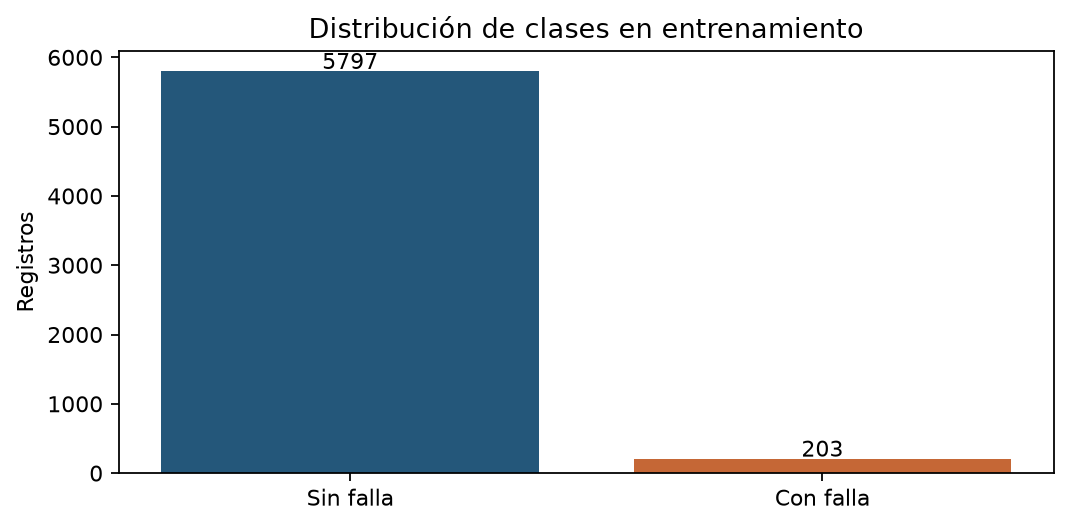

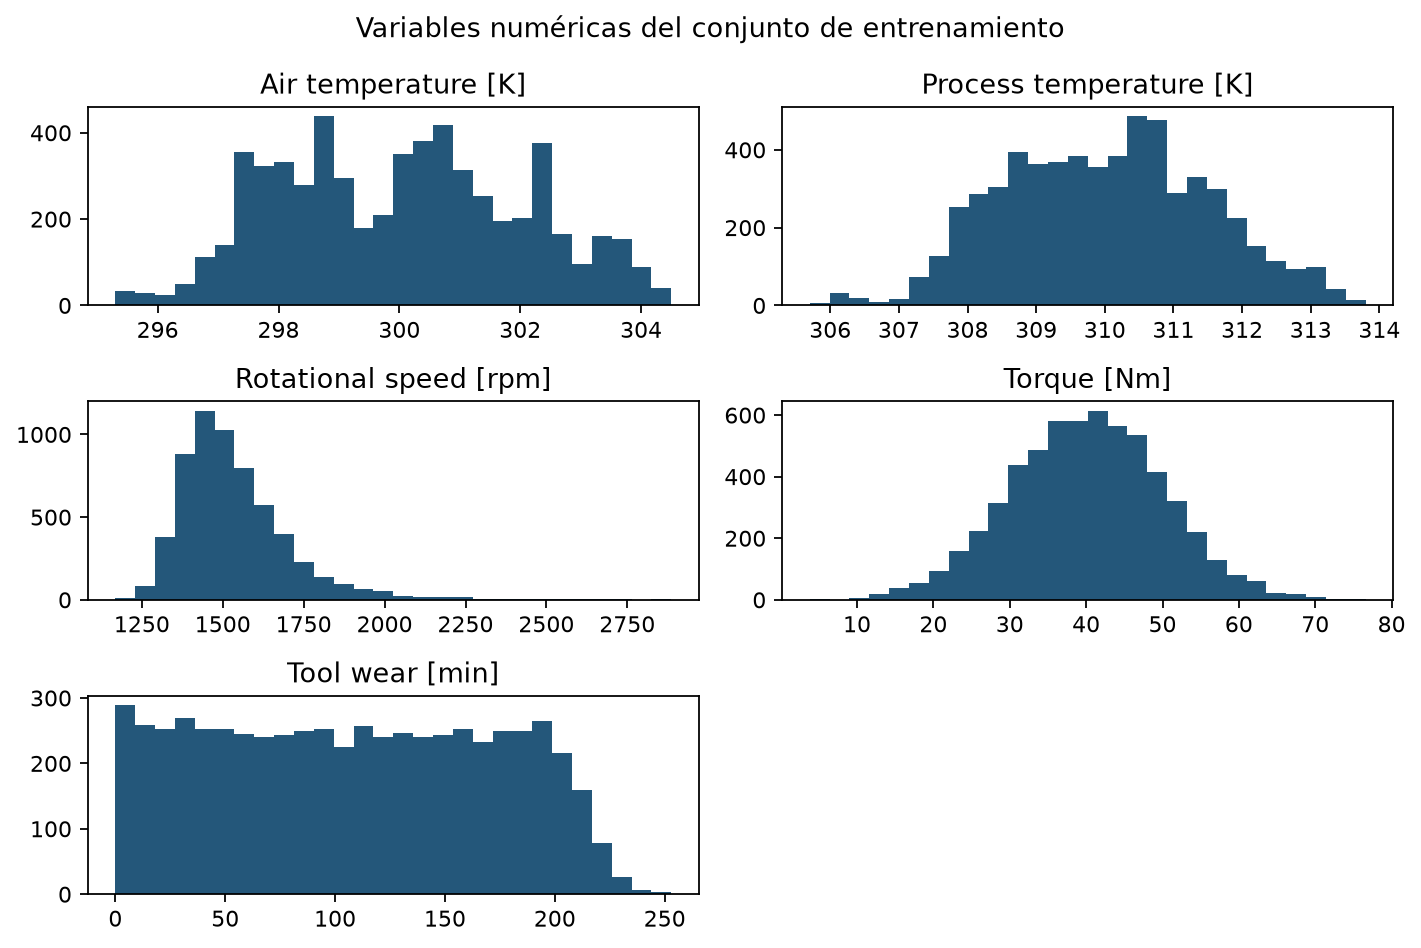

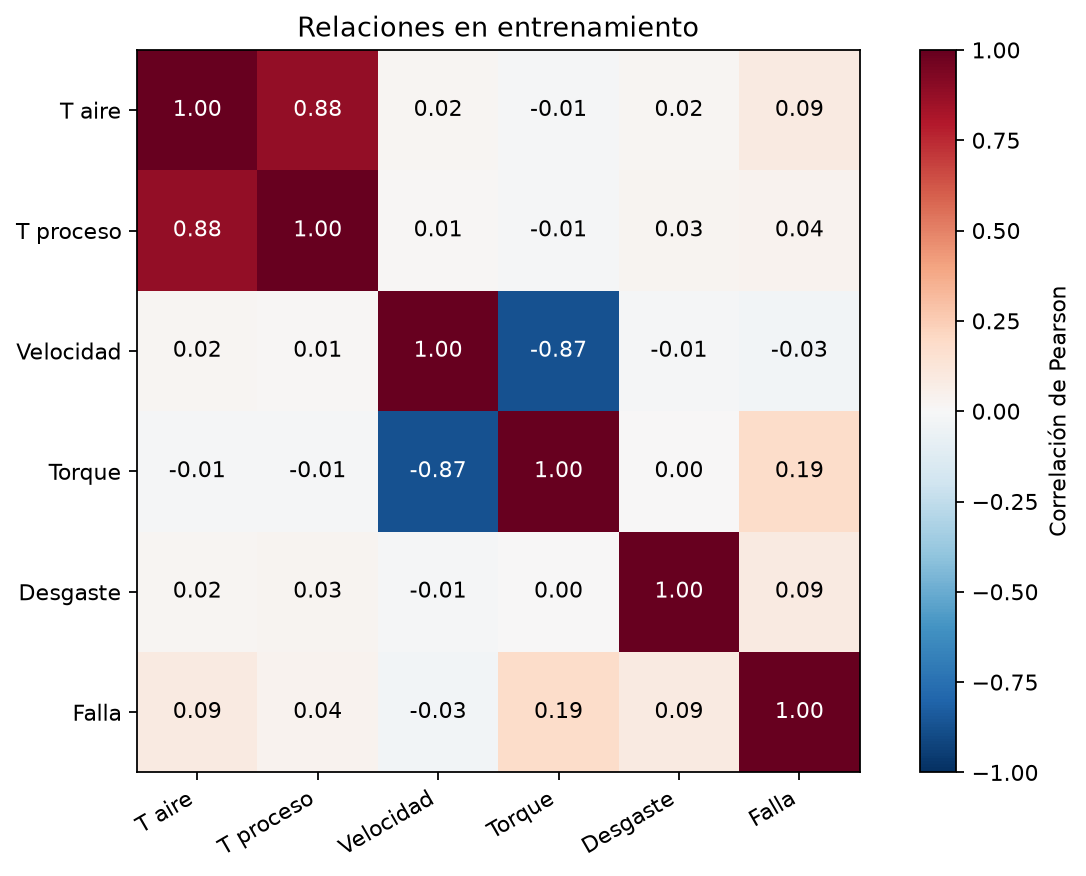

In [5]:
display(pd.read_csv(ROOT/'results/medias_por_falla_entrenamiento.csv'))
for name in ['clases.png','distribuciones.png','correlaciones.png']:
    display(Image(filename=str(ROOT/'results/figures'/name)))

## 3 Carga del Data Mart

In [6]:
# Data Mart en estrella: una observación por fila, sin inventar fechas ni máquinas.
schema='''PRAGMA foreign_keys=ON;
DROP TABLE IF EXISTS fact_operacion;
DROP TABLE IF EXISTS dim_tipo;
DROP TABLE IF EXISTS dim_estado;
CREATE TABLE dim_tipo(tipo_id INTEGER PRIMARY KEY, tipo TEXT UNIQUE NOT NULL, calidad TEXT NOT NULL);
CREATE TABLE dim_estado(estado_id INTEGER PRIMARY KEY, descripcion TEXT NOT NULL);
CREATE TABLE fact_operacion(udi INTEGER PRIMARY KEY, product_id TEXT NOT NULL,
 tipo_id INTEGER NOT NULL REFERENCES dim_tipo(tipo_id), estado_id INTEGER NOT NULL REFERENCES dim_estado(estado_id),
 air_temperature_k REAL, process_temperature_k REAL, rotational_speed_rpm INTEGER, torque_nm REAL,
 tool_wear_min INTEGER, twf INTEGER, hdf INTEGER, pwf INTEGER, osf INTEGER, rnf INTEGER);
'''
(ROOT/'sql/esquema.sql').write_text(schema,encoding='utf-8')
with sqlite3.connect(ROOT/'data/processed/mantenimiento.sqlite') as con:
    con.executescript(schema)
    con.executemany('INSERT INTO dim_tipo VALUES(?,?,?)',[(1,'L','Baja'),(2,'M','Media'),(3,'H','Alta')])
    con.executemany('INSERT INTO dim_estado VALUES(?,?)',[(0,'Sin falla'),(1,'Con falla')])
    records=[(int(r[0]),r[1],{'L':1,'M':2,'H':3}[r[2]],int(r[8]),*r[3:8],*r[9:14]) for r in df.itertuples(index=False,name=None)]
    con.executemany('INSERT INTO fact_operacion VALUES('+','.join(['?']*14)+')',records)
    assert con.execute('SELECT COUNT(*) FROM fact_operacion').fetchone()[0]==len(df)
    assert not con.execute('PRAGMA foreign_key_check').fetchall()
    query='''SELECT t.tipo, COUNT(*) registros, SUM(f.estado_id) fallas,
 ROUND(100.0*SUM(f.estado_id)/COUNT(*),2) porcentaje_fallas, ROUND(AVG(f.torque_nm),2) torque_medio
 FROM fact_operacion f JOIN dim_tipo t USING(tipo_id) GROUP BY t.tipo ORDER BY t.tipo;'''
    (ROOT/'sql/consultas.sql').write_text(query,encoding='utf-8')
    csv(pd.read_sql_query(query,con),'results/resumen_datamart.csv')

In [7]:
display(pd.read_csv(ROOT/'results/resumen_datamart.csv'))

,tipo,registros,fallas,porcentaje_fallas,torque_medio
0,H,1003,21,2.09,39.84
1,L,6000,235,3.92,40.00
2,M,2997,83,2.77,40.02


## 4 Preparación y métricas

In [8]:
def pipeline(model,cols):
    prep=ColumnTransformer([('tipo',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['Type']),('numericas',StandardScaler(),[c for c in cols if c!='Type'])])
    return Pipeline([('preparacion',prep),('modelo',model)])
def regmetrics(y,p):return {'MAE':mean_absolute_error(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),'R2':r2_score(y,p)}
def clsmetrics(y,p,prob):return {'accuracy':accuracy_score(y,p),'precision':precision_score(y,p,zero_division=0),'recall':recall_score(y,p,zero_division=0),'F1':f1_score(y,p,zero_division=0),'F2':fbeta_score(y,p,beta=2,zero_division=0),'AP':average_precision_score(y,prob),'ROC_AUC':roc_auc_score(y,prob)}

## 5 Entrenamiento y búsqueda de parámetros

In [9]:
regcols=[c for c in features if c!='Torque [Nm]']; yreg=df['Torque [Nm]']; ycls=df['Machine failure']
reg_models={'Media':pipeline(DummyRegressor(),regcols),'Lineal':pipeline(LinearRegression(),regcols),'Bosque':pipeline(RandomForestRegressor(n_estimators=120,random_state=42,n_jobs=2),regcols)}
cls_models={'Mayoritaria':pipeline(DummyClassifier(strategy='most_frequent'),features),'Logistica':pipeline(LogisticRegression(class_weight='balanced',max_iter=2000,random_state=42),features),'Bosque':pipeline(RandomForestClassifier(n_estimators=120,class_weight='balanced',random_state=42,n_jobs=2),features)}
grids={'regresion':{'modelo__max_depth':[8,None],'modelo__min_samples_leaf':[1,4]},'clasificacion':{'modelo__max_depth':[8,None],'modelo__min_samples_leaf':[1,4]}}
searches={}; rowsreg=[]; rowscls=[]
for task,models,cols,y in [('regresion',reg_models,regcols,yreg),('clasificacion',cls_models,features,ycls)]:
    for name,m in list(models.items()):
        print(task,name,flush=True)
        if name=='Bosque':
            cv=KFold(3,shuffle=True,random_state=42) if task=='regresion' else StratifiedKFold(3,shuffle=True,random_state=42)
            gs=GridSearchCV(m,grids[task],scoring='neg_root_mean_squared_error' if task=='regresion' else 'average_precision',cv=cv,n_jobs=1)
            gs.fit(df.loc[train,cols],y.loc[train]); m=gs.best_estimator_; models[name]=m
            csv(pd.DataFrame(gs.cv_results_),f'results/busqueda_{task}.csv')
            searches[task]={'parametros':gs.best_params_,'puntuacion_cv':gs.best_score_}
        else:m.fit(df.loc[train,cols],y.loc[train])
        if task=='regresion': rowsreg.append({'modelo':name,**regmetrics(y.loc[val],m.predict(df.loc[val,cols]))})
        else:
            prob=m.predict_proba(df.loc[val,cols])[:,1]
            rowscls.append({'modelo':name,'umbral':.5,**clsmetrics(y.loc[val],(prob>=.5).astype(int),prob)})

regresion Media


regresion Lineal


regresion Bosque


clasificacion Mayoritaria


clasificacion Logistica


clasificacion

 Bosque


In [10]:
print(json.dumps(searches,indent=2))

{
  "regresion": {
    "parametros": {
      "modelo__max_depth": 8,
      "modelo__min_samples_leaf": 1
    },
    "puntuacion_cv": -3.9390207758734834
  },
  "clasificacion": {
    "parametros": {
      "modelo__max_depth": null,
      "modelo__min_samples_leaf": 1
    },
    "puntuacion_cv": 0.671586645788912
  }
}


## 6 Selección en validación y umbral

In [11]:
regtable=pd.DataFrame(rowsreg); clstable=pd.DataFrame(rowscls)
csv(regtable,'results/comparacion_regresion_validacion.csv'); csv(clstable,'results/comparacion_clasificacion_validacion.csv')
bestreg=regtable.sort_values('RMSE').iloc[0]['modelo']; bestcls=clstable.sort_values('AP',ascending=False).iloc[0]['modelo']
rmodel=reg_models[bestreg]; cmodel=cls_models[bestcls]
probval=cmodel.predict_proba(df.loc[val,features])[:,1]
thresholds=pd.DataFrame([{'umbral':float(t),**clsmetrics(ycls.loc[val],(probval>=t).astype(int),probval)} for t in np.arange(.05,.851,.025)])
csv(thresholds,'results/ajuste_umbral_validacion.csv')
threshold=float(thresholds.sort_values(['F2','precision','umbral'],ascending=[False,False,False]).iloc[0].umbral)

In [12]:
display(regtable)
display(clstable)
print('Umbral fijado en validación:', threshold)

,modelo,MAE,RMSE,R2
0,Media,7.945577,9.917079,-0.000154
1,Lineal,3.638742,4.774204,0.768206
2,Bosque,2.992395,3.949089,0.841404


,modelo,umbral,accuracy,precision,recall,F1,F2,AP,ROC_AUC
0,Mayoritaria,0.5,0.9660,0.000000,0.000000,0.000000,0.000000,0.034000,0.500000
1,Logistica,0.5,0.8410,0.150838,0.794118,0.253521,0.428571,0.407168,0.881051
2,Bosque,0.5,0.9785,0.719298,0.602941,0.656000,0.623100,0.674032,0.948632


Umbral fijado en validación: 0.25000000000000006


## 7 Evaluación final en prueba

In [13]:
# Solo se consulta la prueba después de fijar modelos y umbral.
rp=rmodel.predict(df.loc[test,regcols]); cp=cmodel.predict_proba(df.loc[test,features])[:,1]; pred=(cp>=threshold).astype(int)
cm=confusion_matrix(ycls.loc[test],pred)
result={'regresion':{'modelo':bestreg,**regmetrics(yreg.loc[test],rp)},'clasificacion':{'modelo':bestcls,'umbral':threshold,**clsmetrics(ycls.loc[test],pred,cp),'matriz_confusion':cm.tolist()},'busquedas':searches,'semilla':42,'versiones':{'python':platform.python_version(),'scikit-learn':sklearn.__version__,'pandas':pd.__version__,'numpy':np.__version__}}
savejson('metricas_prueba.json',result)
csv(pd.DataFrame({'UDI':df.loc[test,'UDI'],'torque_real':yreg.loc[test],'torque_estimado':rp,'falla_real':ycls.loc[test],'probabilidad_falla':cp,'falla_predicha':pred}),'results/predicciones_prueba.csv')

In [14]:
print(json.dumps(result,indent=2))

{
  "regresion": {
    "modelo": "Bosque",
    "MAE": 3.0188933391269828,
    "RMSE": 3.947958090905844,
    "R2": 0.8383137448012568
  },
  "clasificacion": {
    "modelo": "Bosque",
    "umbral": 0.25000000000000006,
    "accuracy": 0.967,
    "precision": 0.5087719298245614,
    "recall": 0.8529411764705882,
    "F1": 0.6373626373626373,
    "F2": 0.7512953367875648,
    "AP": 0.6963622417209783,
    "ROC_AUC": 0.9698118377785898,
    "matriz_confusion": [
      [
        1876,
        56
      ],
      [
        10,
        58
      ]
    ]
  },
  "busquedas": {
    "regresion": {
      "parametros": {
        "modelo__max_depth": 8,
        "modelo__min_samples_leaf": 1
      },
      "puntuacion_cv": -3.9390207758734834
    },
    "clasificacion": {
      "parametros": {
        "modelo__max_depth": null,
        "modelo__min_samples_leaf": 1
      },
      "puntuacion_cv": 0.671586645788912
    }
  },
  "semilla": 42,
  "versiones": {
    "python": "3.12.14",
    "scikit-learn":

## 8 Guardar modelos y graficar

In [15]:
joblib.dump(rmodel,ROOT/'models/regresion.joblib'); joblib.dump({'pipeline':cmodel,'umbral':threshold},ROOT/'models/clasificacion.joblib')
ConfusionMatrixDisplay(cm,display_labels=['Sin falla','Con falla']).plot(cmap='Blues',colorbar=False); plt.title('Clasificación en prueba'); fig('matriz_confusion.png')
PrecisionRecallDisplay.from_predictions(ycls.loc[test],cp,name=bestcls); plt.title('Precisión y recall en prueba'); fig('precision_recall.png')
plt.figure(figsize=(6,4)); plt.scatter(yreg.loc[test],rp,alpha=.3,s=9,color='#24577a'); lim=[yreg.loc[test].min(),yreg.loc[test].max()]; plt.plot(lim,lim,'--',color='#c56736'); plt.xlabel('Torque real [Nm]'); plt.ylabel('Torque estimado [Nm]'); plt.title('Regresión en prueba'); fig('regresion.png')

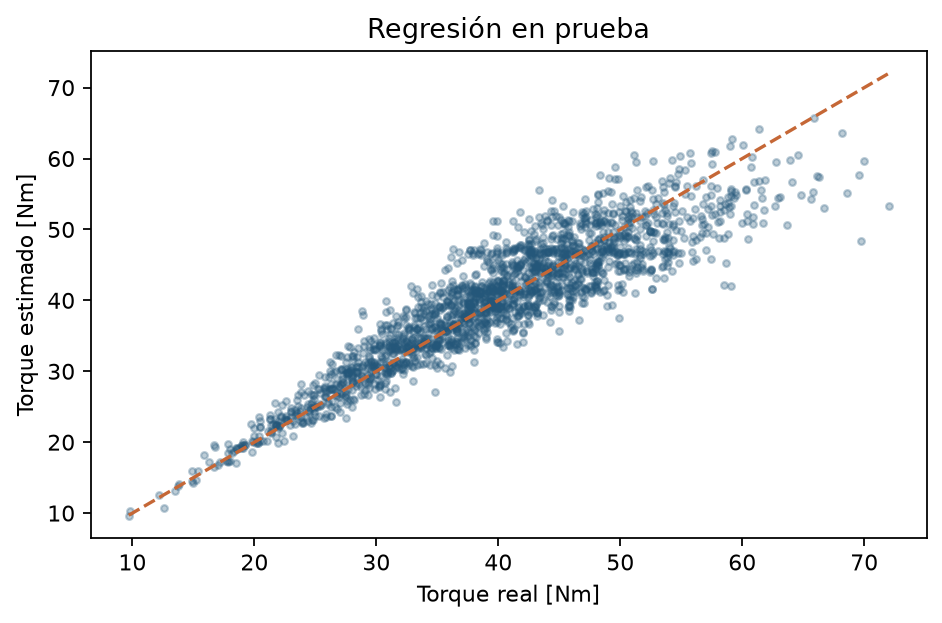

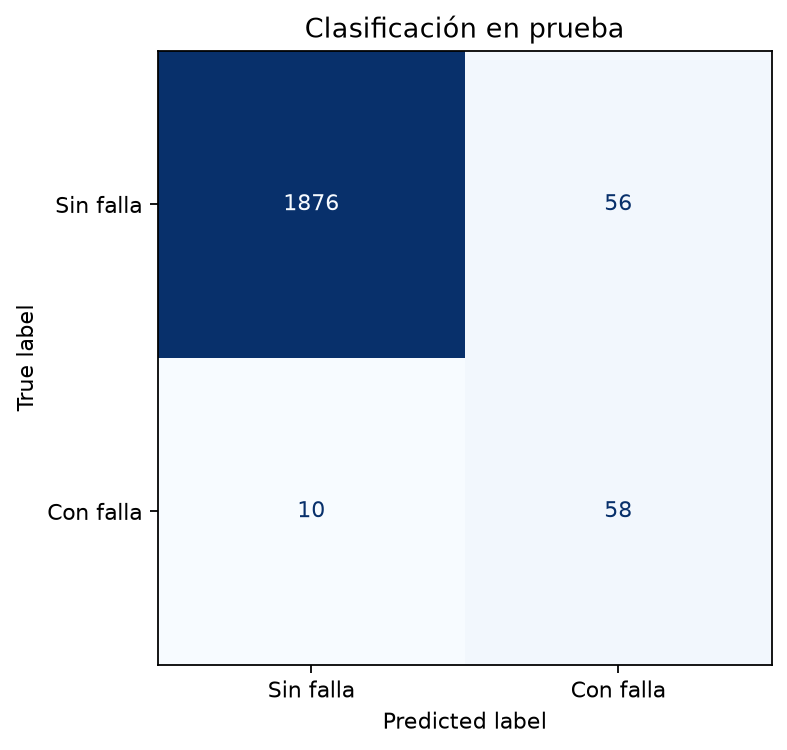

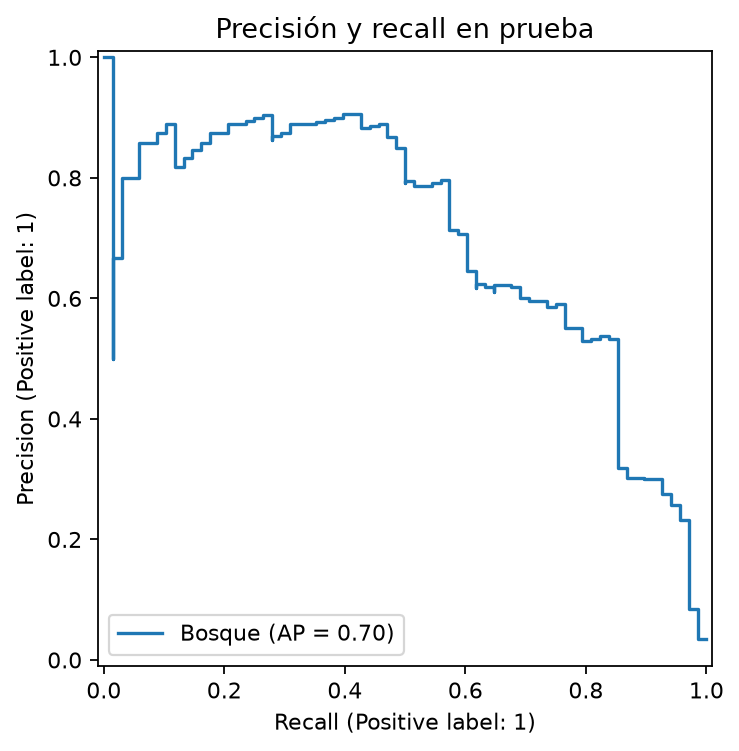

In [16]:
for name in ['regresion.png','matriz_confusion.png','precision_recall.png']:
    display(Image(filename=str(ROOT/'results/figures'/name)))

## 9 Importancia y comprobaciones

In [17]:
importance=permutation_importance(cmodel,df.loc[val,features],ycls.loc[val],scoring='average_precision',n_repeats=5,random_state=42,n_jobs=1)
csv(pd.DataFrame({'variable':features,'reduccion_AP_media':importance.importances_mean,'desviacion':importance.importances_std}).sort_values('reduccion_AP_media',ascending=False),'results/importancia_validacion.csv')
assert np.allclose(joblib.load(ROOT/'models/regresion.joblib').predict(df.loc[test,regcols]),rp)
loaded=joblib.load(ROOT/'models/clasificacion.joblib'); assert np.allclose(loaded['pipeline'].predict_proba(df.loc[test,features])[:,1],cp)
savejson('verificacion.json',{'esquema':True,'integridad_sqlite':True,'particiones_disjuntas':True,'modelos_recargables':True,'n_predicciones':len(rp)})
print(json.dumps(result,indent=2),flush=True)

{
  "regresion": {
    "modelo": "Bosque",
    "MAE": 3.0188933391269828,
    "RMSE": 3.947958090905844,
    "R2": 0.8383137448012568
  },
  "clasificacion": {
    "modelo": "Bosque",
    "umbral": 0.25000000000000006,
    "accuracy": 0.967,
    "precision": 0.5087719298245614,
    "recall": 0.8529411764705882,
    "F1": 0.6373626373626373,
    "F2": 0.7512953367875648,
    "AP": 0.6963622417209783,
    "ROC_AUC": 0.9698118377785898,
    "matriz_confusion": [
      [
        1876,
        56
      ],
      [
        10,
        58
      ]
    ]
  },
  "busquedas": {
    "regresion": {
      "parametros": {
        "modelo__max_depth": 8,
        "modelo__min_samples_leaf": 1
      },
      "puntuacion_cv": -3.9390207758734834
    },
    "clasificacion": {
      "parametros": {
        "modelo__max_depth": null,
        "modelo__min_samples_leaf": 1
      },
      "puntuacion_cv": 0.671586645788912
    }
  },
  "semilla": 42,
  "versiones": {
    "python": "3.12.14",
    "scikit-learn":

In [18]:
display(pd.read_csv(ROOT/'results/importancia_validacion.csv'))

,variable,reduccion_AP_media,desviacion
0,Torque [Nm],0.438086,0.013584
1,Rotational speed [rpm],0.336572,0.032323
2,Air temperature [K],0.273577,0.024180
3,Tool wear [min],0.248210,0.036285
4,Process temperature [K],0.120759,0.022830
5,Type,0.001729,0.031199


## Interpretación
El clasificador detecta 58 de 68 fallas de prueba, con 56 falsas alarmas. El MAE de torque es 3.019 Nm. Estas cifras no demuestran anticipación temporal ni validez industrial. Las 27 discrepancias de etiquetas se conservan. Consulte el informe para las decisiones, límites y referencias.